<a href="https://colab.research.google.com/github/anasabrinars/Fase-1-FIAP/blob/main/Crescimento_e_Receita2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
# imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#bases

df_orders = pd.read_csv('/content/olist_orders_dataset.csv')
df_pagamentos = pd.read_csv('/content/olist_order_payments_dataset.csv')
df_order_items = pd.read_csv('/content/olist_order_items_dataset.csv')

In [23]:
# Visualizar as primeiras linhas
print(df_orders.head())
print(df_order_items.head())

                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00           2018-08

In [24]:
# Converter a coluna para data
df_orders["order_purchase_timestamp"] = pd.to_datetime(
    df_orders["order_purchase_timestamp"]
)

# Filtrar pedidos entregues
orders_entregues = df_orders[
    df_orders["order_status"] == "delivered"
].copy()

# Criar coluna com o mês da compra
orders_entregues["mes"] = (
    orders_entregues["order_purchase_timestamp"]
    .dt.to_period("M")
)


In [25]:

df = orders_entregues.merge(
    df_order_items,
    on="order_id",
    how="inner",
    validate="one_to_many"
)

# Visualizar o resultado
df.head()


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,mes,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,2017-10,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,2018-07,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,2018-08,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,2017-11,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,2018-02,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [26]:

evolucao_mensal = (
    df.groupby("mes")
    .agg(
        pedidos=("order_id", "nunique"),
        receita=("price", "sum")
    )
    .reset_index()
)

# Calcular ticket médio
evolucao_mensal["ticket_medio"] = (
    evolucao_mensal["receita"] /
    evolucao_mensal["pedidos"]
)

# Arredondar os valores
evolucao_mensal["receita"] = (
    evolucao_mensal["receita"].round(2)
)

evolucao_mensal["ticket_medio"] = (
    evolucao_mensal["ticket_medio"].round(2)
)

# Visualizar resultado
print(evolucao_mensal)


        mes  pedidos    receita  ticket_medio
0   2016-09        1     134.97        134.97
1   2016-10      265   40325.11        152.17
2   2016-12        1      10.90         10.90
3   2017-01      750  111798.36        149.06
4   2017-02     1653  234223.40        141.70
5   2017-03     2546  359198.85        141.08
6   2017-04     2303  340669.68        147.92
7   2017-05     3546  489338.25        138.00
8   2017-06     3135  421923.37        134.58
9   2017-07     3872  481604.52        124.38
10  2017-08     4193  554699.70        132.29
11  2017-09     4150  607399.67        146.36
12  2017-10     4478  648247.65        144.76
13  2017-11     7289  987765.37        135.51
14  2017-12     5513  726033.19        131.69
15  2018-01     7069  924645.00        130.80
16  2018-02     6555  826437.13        126.08
17  2018-03     7003  953356.25        136.14
18  2018-04     6798  973534.09        143.21
19  2018-05     6749  977544.69        144.84
20  2018-06     6099  856077.86   

<Figure size 1200x500 with 0 Axes>

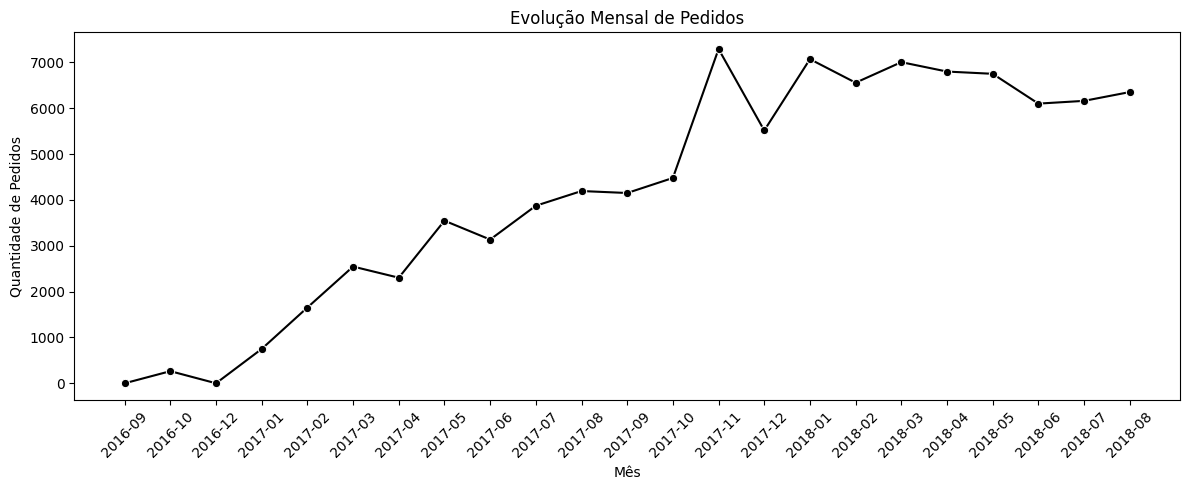

In [41]:
# visualização gráfico evolução mensal pedidos
plt.figure(figsize=(12, 5))


fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(
    data=evolucao_mensal,
    x=evolucao_mensal["mes"].astype(str),
    y="pedidos",
    marker="o",
    color="black",
    ax=ax
)

# Deixar o fundo transparente
fig.patch.set_facecolor("none")
ax.set_facecolor("none")

plt.title("Evolução Mensal de Pedidos")
plt.xlabel("Mês")
plt.ylabel("Quantidade de Pedidos")
plt.xticks(rotation=45)
plt.tight_layout()

# Salvar imagem com fundo transparente
plt.savefig(
    "evolucao_pedidos.png",
    transparent=True,
    dpi=300,
    bbox_inches="tight"
)

plt.show()



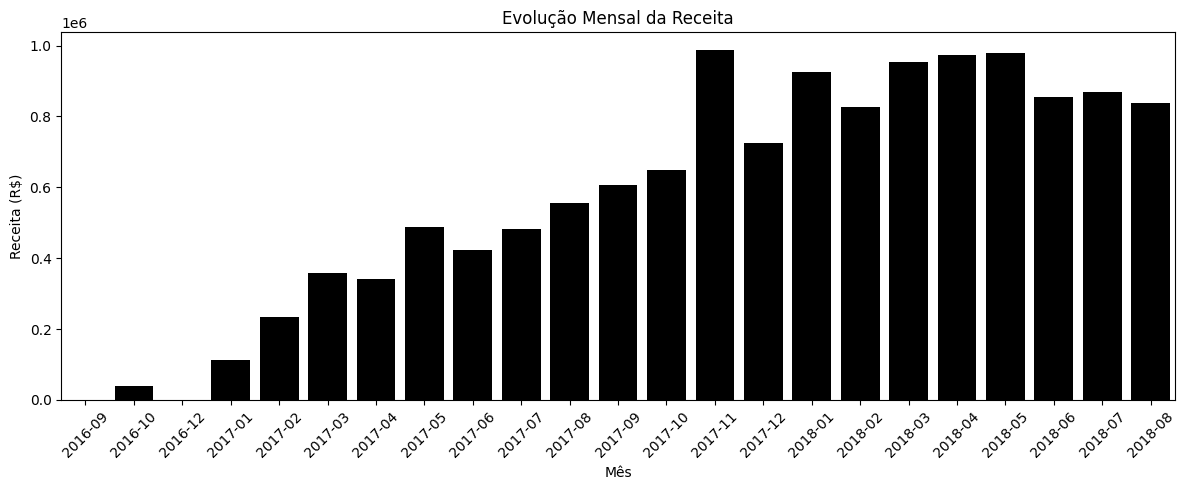

In [40]:
# visualização gráficos evolução mensal receita



fig, ax = plt.subplots(figsize=(12, 5))

sns.barplot(
    data=evolucao_mensal,
    x=evolucao_mensal["mes"].astype(str),
    y="receita",
    color="black",
    ax=ax
)

# Deixar o fundo transparente
fig.patch.set_facecolor("none")
ax.set_facecolor("none")

plt.title("Evolução Mensal da Receita")
plt.xlabel("Mês")
plt.ylabel("Receita (R$)")
plt.xticks(rotation=45)
plt.tight_layout()

# Salvar com fundo transparente
plt.savefig(
    "evolucao_receita.png",
    transparent=True,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


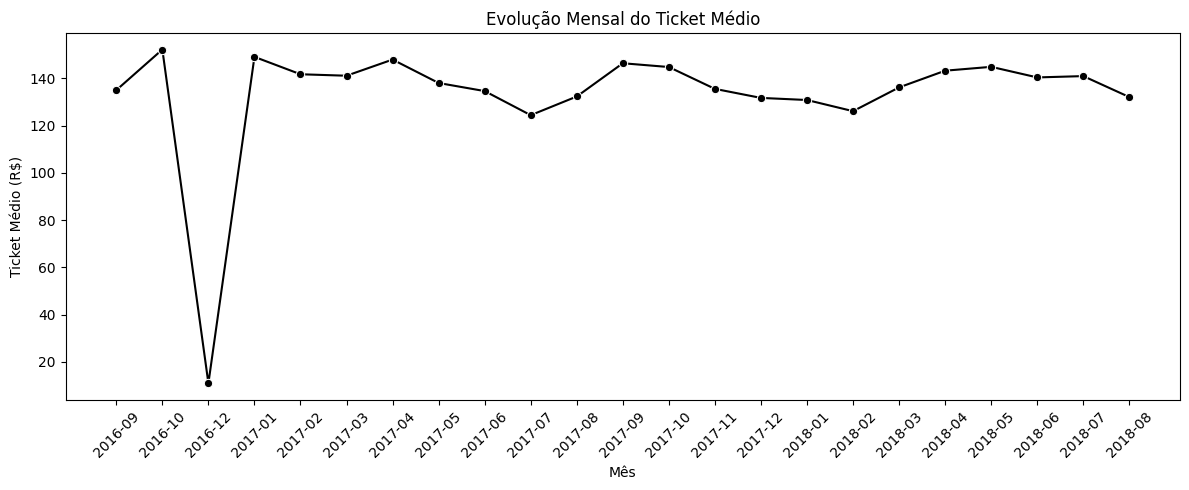

In [42]:
# visualização gráficos evolução mensal ticket médio


fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(
    data=evolucao_mensal,
    x=evolucao_mensal["mes"].astype(str),
    y="ticket_medio",
    marker="o",
    color="black",
    ax=ax
)

# Deixar o fundo transparente
fig.patch.set_facecolor("none")
ax.set_facecolor("none")

plt.title("Evolução Mensal do Ticket Médio")
plt.xlabel("Mês")
plt.ylabel("Ticket Médio (R$)")
plt.xticks(rotation=45)
plt.tight_layout()

# Salvar imagem com fundo transparente
plt.savefig(
    "evolucao_ticket_medio.png",
    transparent=True,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [30]:
# bases

df_products = pd.read_csv('/content/olist_products_dataset.csv')
df_customers = pd.read_csv('/content/olist_customers_dataset.csv')
df_category_translation = pd.read_csv('/content/product_category_name_translation.csv')

In [70]:
import pandas as pd

# Padronizar os nomes das colunas
for base in [df_order_items, df_orders, df_customers, df_products]:
    base.columns = base.columns.str.strip()

# Corrigir o nome da categoria, se necessário
df_products = df_products.rename(
    columns={'product_category_name': 'category_name'}
)

# Cruzar as bases
df = (
    df_order_items
    .merge(
        df_orders[['order_id', 'customer_id', 'order_status']],
        on='order_id',
        how='inner'
    )
    .merge(
        df_customers[['customer_id', 'customer_city', 'customer_state']],
        on='customer_id',
        how='left'
    )
    .merge(
        df_products[['product_id', 'category_name']],
        on='product_id',
        how='left'
    )
)

# Renomear as colunas geográficas para português
df = df.rename(columns={
    'customer_city': 'cidade',
    'customer_state': 'estado'
})

# Considerar apenas pedidos entregues
df = df[df['order_status'] == 'delivered'].copy()

# Verificar o resultado
display(df.head())

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,cidade,estado,category_name
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,campos dos goytacazes,RJ,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,santa fe do sul,SP,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,para de minas,MG,moveis_decoracao
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,atibaia,SP,perfumaria
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,varzea paulista,SP,ferramentas_jardim


In [71]:
df['categoria'] = df['category_name'].fillna('Sem categoria')

df['estado'] = df['estado'].str.upper().str.strip()
df['cidade'] = df['cidade'].str.strip().str.title()

In [72]:
participacao = (
    df.groupby(['estado', 'cidade', 'categoria'], as_index=False)
      .agg(faturamento=('price', 'sum'))
)

participacao['participacao_pct'] = (
    participacao['faturamento'] /
    participacao.groupby(['estado', 'cidade'])['faturamento'].transform('sum')
) * 100

# Mostrar as 5 maiores categorias de cada município
top5 = (
    participacao
    .sort_values('faturamento', ascending=False)
    .groupby(['estado', 'cidade'])
    .head(5)
)

display(top5)

,estado,cidade,categoria,faturamento,participacao_pct
24464,SP,Sao Paulo,beleza_saude,185381.84,9.969141
24466,SP,Sao Paulo,cama_mesa_banho,168275.99,9.049252
24518,SP,Sao Paulo,relogios_presentes,160142.18,8.611847
24485,SP,Sao Paulo,esporte_lazer,140847.97,7.574276
24497,SP,Sao Paulo,informatica_acessorios,139960.84,7.526570
...,...,...,...,...,...
11736,PR,Juranda,utilidades_domesticas,6.00,14.669927
7439,MG,Recreio,eletronicos,5.99,2.260548
12422,PR,Sabaudia,fashion_underwear_e_moda_praia,5.90,100.000000
16134,RS,Polo Petroquimico De Triunfo,papelaria,5.60,100.000000


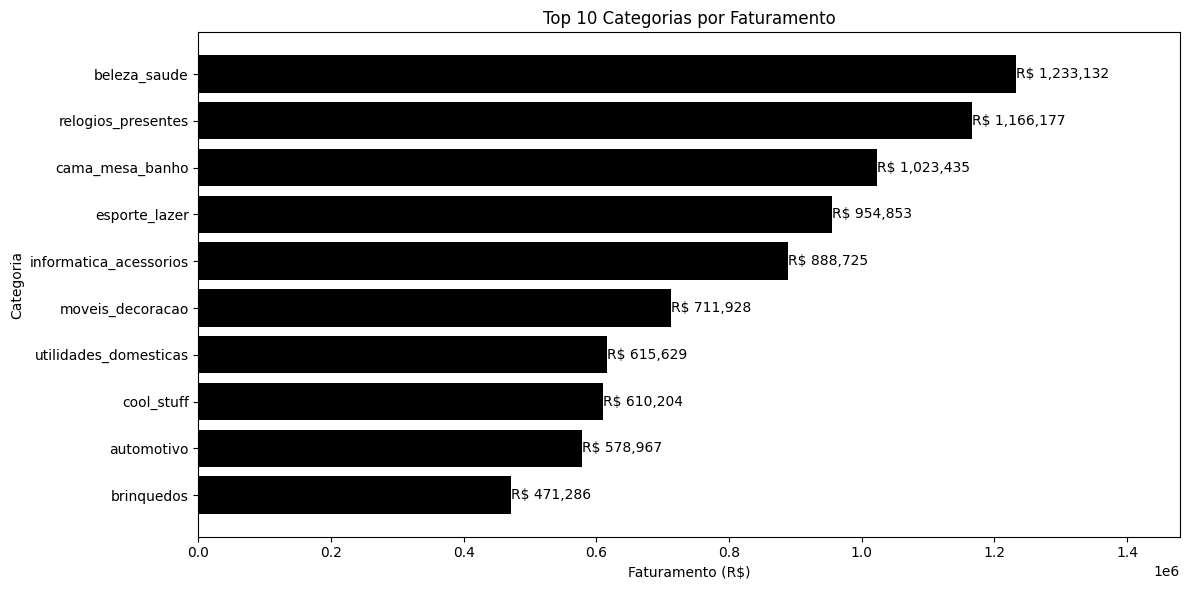

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Faturamento por categoria
top_categorias = (
    df.groupby('categoria')['price']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.barh(
    top_categorias.index,
    top_categorias.values,
    color='black'
)

# Valores nas barras
for bar in bars:
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height()/2,
        f'R$ {bar.get_width():,.0f}',
        va='center',
        ha='left'
    )

ax.set_title('Top 10 Categorias por Faturamento')
ax.set_xlabel('Faturamento (R$)')
ax.set_ylabel('Categoria')

ax.set_xlim(0, top_categorias.max() * 1.2)

# Fundo transparente
fig.patch.set_alpha(0)
ax.patch.set_alpha(0)

plt.tight_layout()
plt.savefig(
    'grafico_categorias.png',
    dpi=300,
    transparent=True,
    bbox_inches='tight'
)
plt.show()

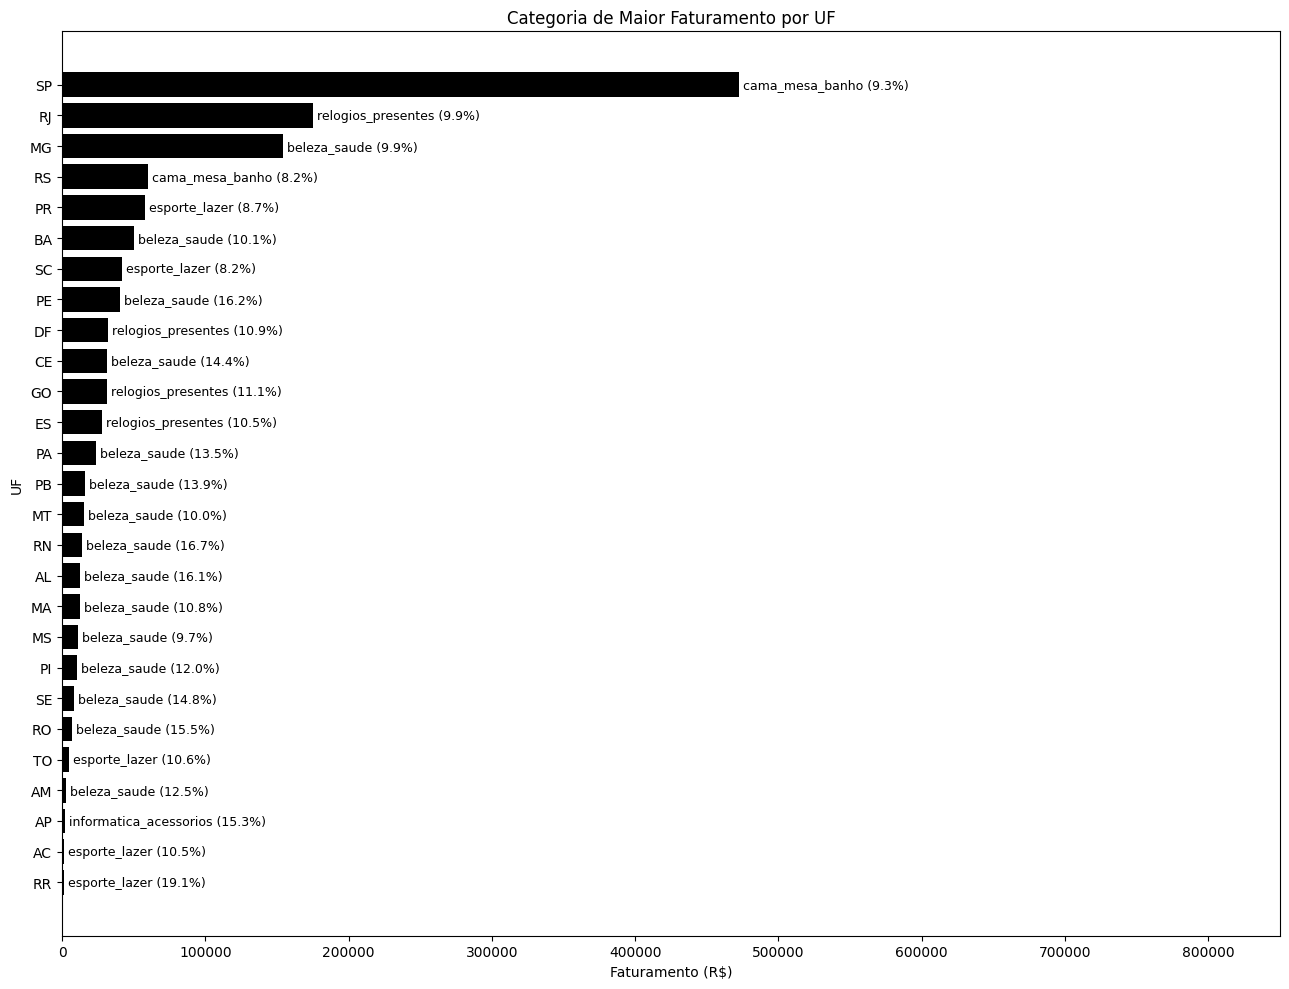

In [78]:
# Faturamento por UF e categoria
categorias_uf = (
    df.groupby(['estado', 'categoria'], as_index=False)
    .agg(faturamento=('price', 'sum'))
)

# Total de faturamento de cada UF
categorias_uf['total_uf'] = (
    categorias_uf.groupby('estado')['faturamento']
    .transform('sum')
)

# Participação percentual
categorias_uf['participacao_pct'] = (
    categorias_uf['faturamento'] /
    categorias_uf['total_uf'] * 100
)

# Maior categoria de cada UF
maior_categoria_uf = (
    categorias_uf
    .sort_values('faturamento', ascending=False)
    .drop_duplicates('estado')
    .sort_values('faturamento')
)

fig, ax = plt.subplots(figsize=(13, 10))

bars = ax.barh(
    maior_categoria_uf['estado'],
    maior_categoria_uf['faturamento'],
    color='black'
)

# Nome da categoria e participação
for bar, (_, linha) in zip(
    bars,
    maior_categoria_uf.iterrows()
):
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height()/2,
        f" {linha['categoria']} ({linha['participacao_pct']:.1f}%)",
        va='center',
        fontsize=9
    )

ax.set_xlim(
    0,
    maior_categoria_uf['faturamento'].max() * 1.8
)

ax.set_title('Categoria de Maior Faturamento por UF')
ax.set_xlabel('Faturamento (R$)')
ax.set_ylabel('UF')

fig.patch.set_alpha(0)
ax.patch.set_alpha(0)

plt.tight_layout()
plt.savefig(
    'grafico_categorias.png',
    dpi=300,
    transparent=True,
    bbox_inches='tight'
)
plt.show()

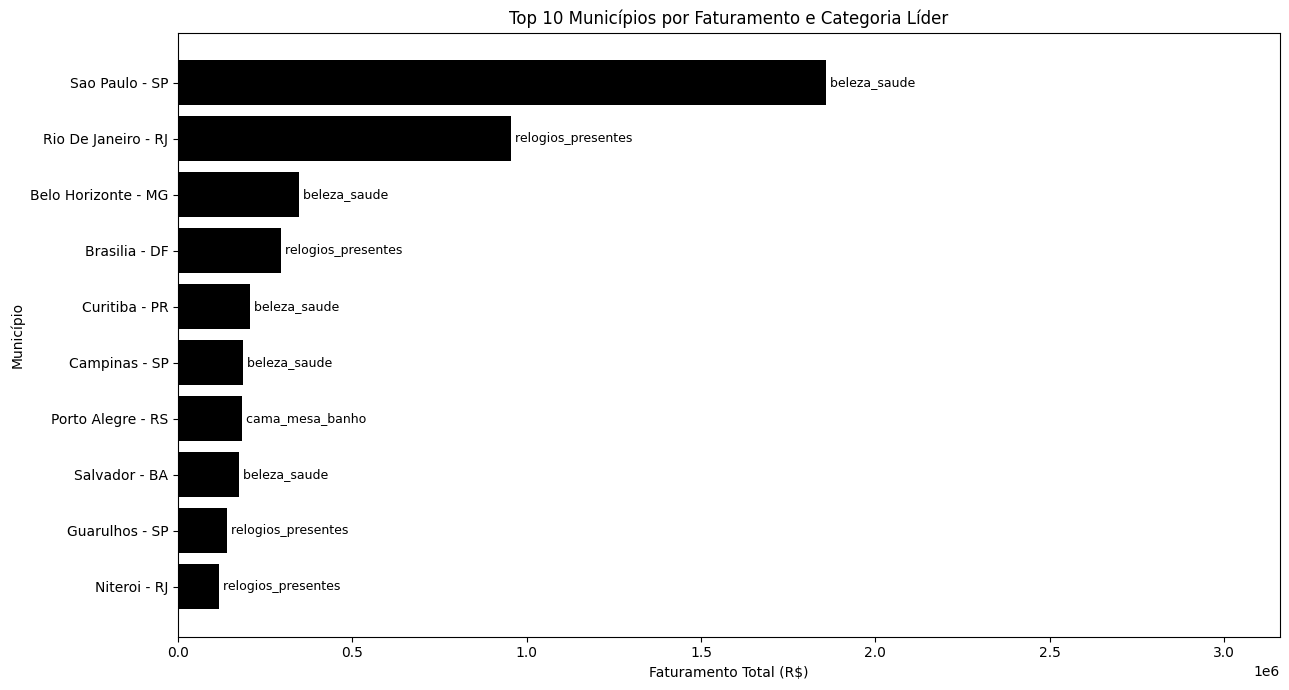

In [77]:
# Faturamento por município
faturamento_municipio = (
    df.groupby(['estado', 'cidade'], as_index=False)
    .agg(faturamento_total=('price', 'sum'))
    .sort_values('faturamento_total', ascending=False)
    .head(10)
)

# Faturamento por município e categoria
categorias_municipio = (
    df.groupby(
        ['estado', 'cidade', 'categoria'],
        as_index=False
    )
    .agg(faturamento=('price', 'sum'))
)

# Categoria líder de cada município
maior_categoria_municipio = (
    categorias_municipio
    .sort_values('faturamento', ascending=False)
    .drop_duplicates(['estado', 'cidade'])
)

# Filtrar os 10 municípios de maior faturamento
top_municipios = faturamento_municipio.merge(
    maior_categoria_municipio,
    on=['estado', 'cidade'],
    how='left'
)

top_municipios['municipio_uf'] = (
    top_municipios['cidade'] +
    ' - ' +
    top_municipios['estado']
)

top_municipios = top_municipios.sort_values(
    'faturamento_total'
)

fig, ax = plt.subplots(figsize=(13, 7))

bars = ax.barh(
    top_municipios['municipio_uf'],
    top_municipios['faturamento_total'],
    color='black'
)

for bar, (_, linha) in zip(
    bars,
    top_municipios.iterrows()
):
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height()/2,
        f" {linha['categoria']}",
        va='center',
        fontsize=9
    )

ax.set_xlim(
    0,
    top_municipios['faturamento_total'].max() * 1.7
)

ax.set_title(
    'Top 10 Municípios por Faturamento e Categoria Líder'
)
ax.set_xlabel('Faturamento Total (R$)')
ax.set_ylabel('Município')

fig.patch.set_alpha(0)
ax.patch.set_alpha(0)

plt.tight_layout()
plt.savefig(
    'grafico_categorias.png',
    dpi=300,
    transparent=True,
    bbox_inches='tight'
)
plt.show()

In [80]:
# Faturamento e quantidade vendida por produto
top_produtos = (
    df.groupby(['product_id', 'categoria'], as_index=False)
    .agg(
        faturamento=('price', 'sum'),
        quantidade_vendida=('product_id', 'size'),
        pedidos=('order_id', 'nunique')
    )
)

# Participação no faturamento total
top_produtos['participacao_pct'] = (
    top_produtos['faturamento'] /
    df['price'].sum() * 100
)

# Selecionar os 10 produtos de maior faturamento
top10_produtos = (
    top_produtos
    .sort_values('faturamento', ascending=False)
    .head(10)
    .copy()
)

# Criar identificação mais curta
top10_produtos['produto'] = (
    top10_produtos['categoria'] +
    ' - ' +
    top10_produtos['product_id'].str[:6]
)

display(top10_produtos)

,product_id,categoria,faturamento,quantidade_vendida,pedidos,participacao_pct,produto
23546,bb50f2e236e5eea0100680137654686c,beleza_saude,63560.00,194,186,0.480732,beleza_saude - bb50f2
13749,6cdd53843498f92890544667809f1595,beleza_saude,53652.30,153,148,0.405796,beleza_saude - 6cdd53
26997,d6160fb7873f184099d9bc95e30376af,pcs,45949.35,33,33,0.347535,pcs - d6160f
26436,d1c427060a0f73f6b889a5c7c61f2ac4,informatica_acessorios,45620.56,332,313,0.345048,informatica_acessorios - d1c427
19290,99a4788cb24856965c36a24e339b6058,cama_mesa_banho,42049.66,477,456,0.318040,cama_mesa_banho - 99a478
7881,3dd2a17168ec895c781a9191c1e95ad7,informatica_acessorios,40782.80,272,253,0.308458,informatica_acessorios - 3dd2a1
4892,25c38557cf793876c5abdd5931f922db,bebes,38907.32,38,38,0.294273,bebes - 25c385
12074,5f504b3a1c75b73d6151be81eb05bdc9,cool_stuff,37733.90,63,63,0.285398,cool_stuff - 5f504b
10616,53b36df67ebb7c41585e8d54d6772e08,relogios_presentes,37454.63,321,304,0.283286,relogios_presentes - 53b36d
21617,aca2eb7d00ea1a7b8ebd4e68314663af,moveis_decoracao,37104.30,520,425,0.280636,moveis_decoracao - aca2eb


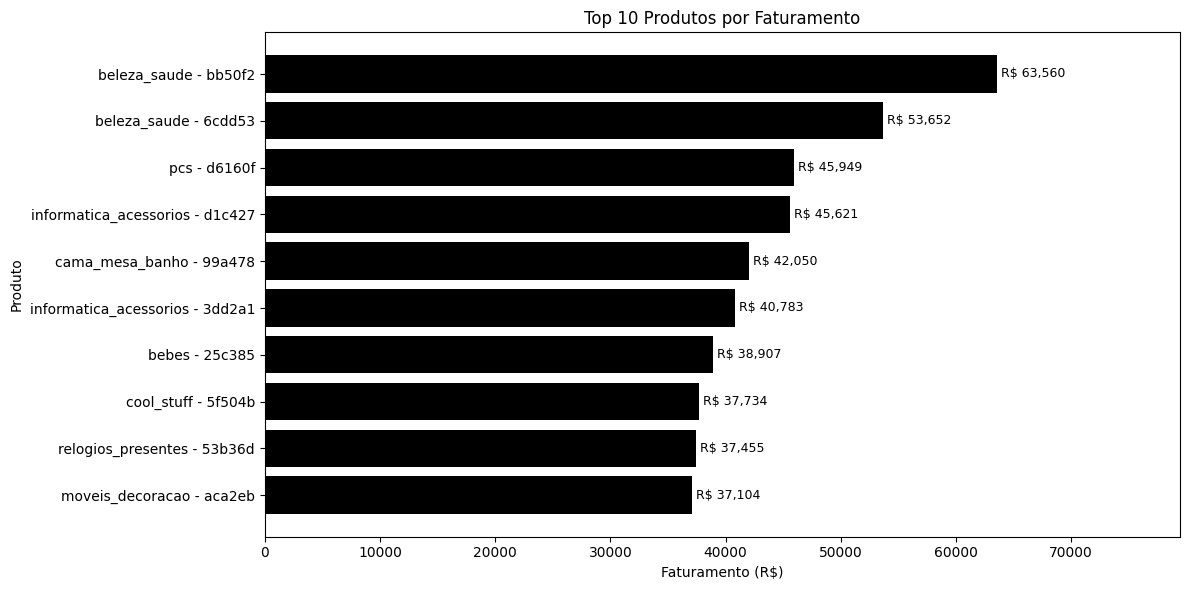

In [81]:
dados = top10_produtos.sort_values('faturamento')

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.barh(
    dados['produto'],
    dados['faturamento'],
    color='black'
)

for bar in bars:
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height()/2,
        f' R$ {bar.get_width():,.0f}',
        va='center',
        fontsize=9
    )

ax.set_xlim(0, dados['faturamento'].max() * 1.25)

ax.set_title('Top 10 Produtos por Faturamento')
ax.set_xlabel('Faturamento (R$)')
ax.set_ylabel('Produto')

fig.patch.set_alpha(0)
ax.patch.set_alpha(0)

plt.tight_layout()
plt.show()

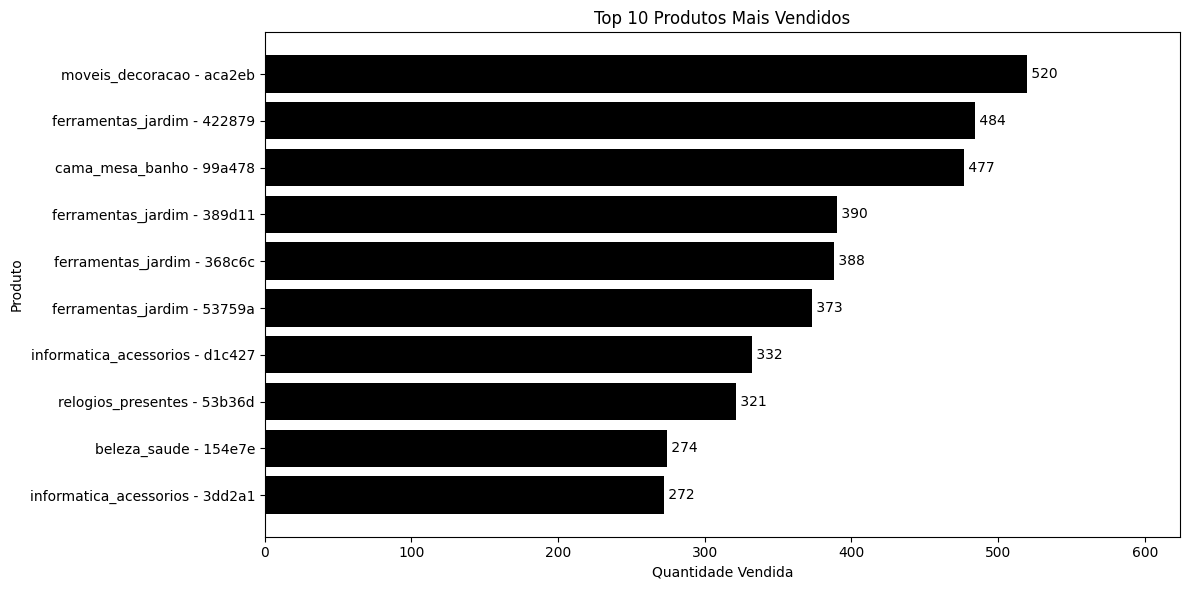

In [88]:
top10_quantidade = (
    top_produtos
    .sort_values('quantidade_vendida', ascending=False)
    .head(10)
    .copy()
)

top10_quantidade['produto'] = (
    top10_quantidade['categoria'] +
    ' - ' +
    top10_quantidade['product_id'].str[:6]
)

dados = top10_quantidade.sort_values('quantidade_vendida')

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.barh(
    dados['produto'],
    dados['quantidade_vendida'],
    color='black'
)

for bar in bars:
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height()/2,
        f' {bar.get_width():,.0f}',
        va='center'
    )

ax.set_xlim(0, dados['quantidade_vendida'].max() * 1.2)

ax.set_title('Top 10 Produtos Mais Vendidos')
ax.set_xlabel('Quantidade Vendida')
ax.set_ylabel('Produto')

fig.patch.set_alpha(0)
ax.patch.set_alpha(0)

plt.tight_layout()
plt.savefig(
    'grafico_categorias.png',
    dpi=300,
    transparent=True,
    bbox_inches='tight'
)
plt.show()

In [83]:
# Faturamento por vendedor
top_sellers = (
    df.groupby('seller_id', as_index=False)
    .agg(
        faturamento=('price', 'sum'),
        quantidade_vendida=('product_id', 'size'),
        pedidos=('order_id', 'nunique')
    )
)

# Participação no faturamento total
top_sellers['participacao_pct'] = (
    top_sellers['faturamento'] /
    df['price'].sum() * 100
)

top10_sellers = (
    top_sellers
    .sort_values('faturamento', ascending=False)
    .head(10)
    .copy()
)

top10_sellers['seller'] = (
    'Seller ' + top10_sellers['seller_id'].str[:6]
)

display(top10_sellers)

,seller_id,faturamento,quantidade_vendida,pedidos,participacao_pct,seller
834,4869f7a5dfa277a7dca6462dcf3b52b2,226987.93,1148,1124,1.716809,Seller 4869f7
982,53243585a1d6dc2643021fd1853d8905,217940.44,400,348,1.648379,Seller 532435
858,4a3ca9315b744ce9f8e9374361493884,196882.12,1949,1772,1.489106,Seller 4a3ca9
2903,fa1c13f2614d7b5c4749cbc52fecda94,190917.14,579,578,1.443990,Seller fa1c13
1480,7c67e1448b00f6e969d365cea6b010ab,186570.05,1355,973,1.411111,Seller 7c67e1
1504,7e93a43ef30c4f03f38b393420bc753a,165981.49,322,319,1.255391,Seller 7e93a4
2543,da8622b14eb17ae2831f4ac5b9dab84a,159816.87,1548,1311,1.208765,Seller da8622
1450,7a67c85e85bb2ce8582c35f2203ad736,139658.69,1155,1145,1.056300,Seller 7a67c8
188,1025f0e2d44d7041d6cf58b6550e0bfa,138208.56,1420,910,1.045332,Seller 1025f0
1758,955fee9216a65b617aa5c0531780ce60,131836.71,1472,1261,0.997139,Seller 955fee


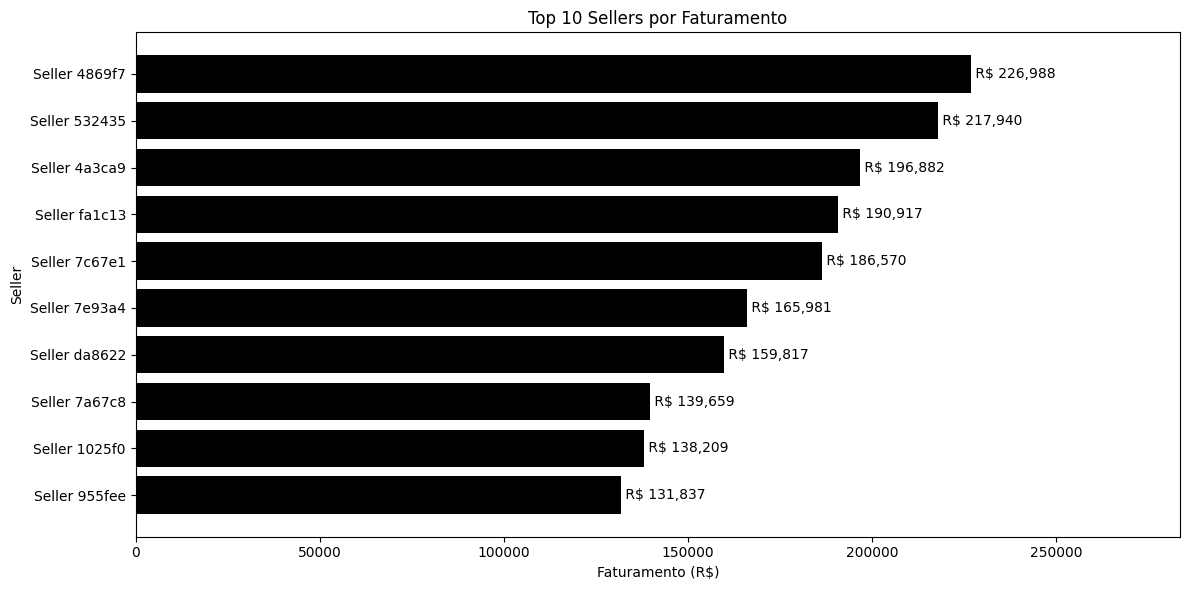

In [84]:
dados = top10_sellers.sort_values('faturamento')

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.barh(
    dados['seller'],
    dados['faturamento'],
    color='black'
)

for bar in bars:
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height()/2,
        f' R$ {bar.get_width():,.0f}',
        va='center'
    )

ax.set_xlim(0, dados['faturamento'].max() * 1.25)

ax.set_title('Top 10 Sellers por Faturamento')
ax.set_xlabel('Faturamento (R$)')
ax.set_ylabel('Seller')

fig.patch.set_alpha(0)
ax.patch.set_alpha(0)

plt.tight_layout()
plt.show()

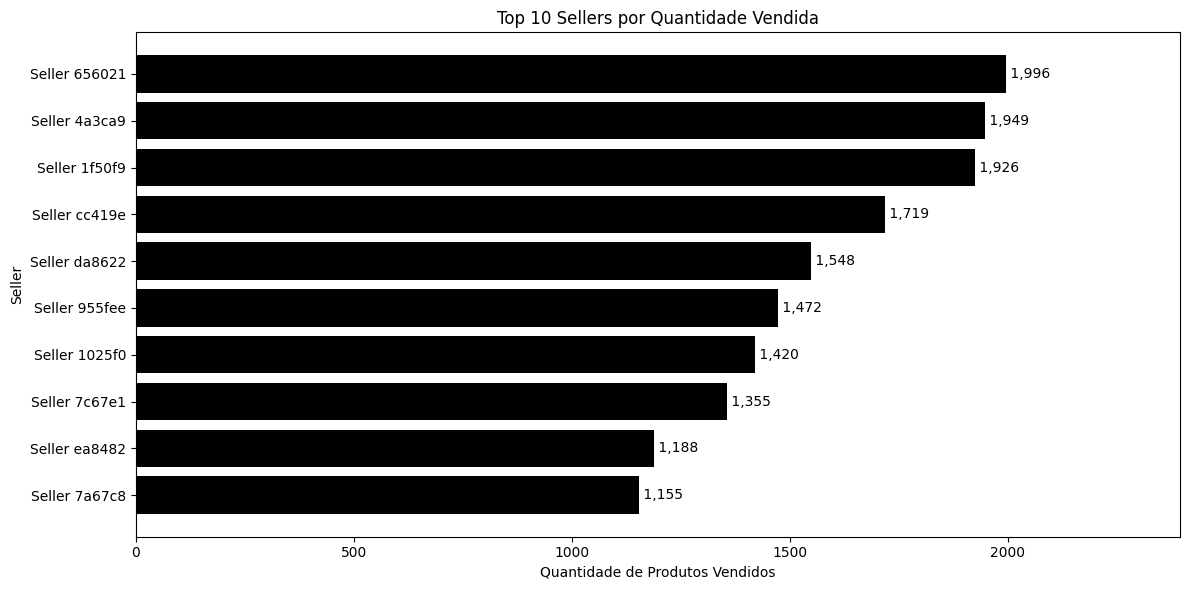

In [85]:
top10_sellers_quantidade = (
    top_sellers
    .sort_values('quantidade_vendida', ascending=False)
    .head(10)
    .copy()
)

top10_sellers_quantidade['seller'] = (
    'Seller ' +
    top10_sellers_quantidade['seller_id'].str[:6]
)

dados = top10_sellers_quantidade.sort_values('quantidade_vendida')

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.barh(
    dados['seller'],
    dados['quantidade_vendida'],
    color='black'
)

for bar in bars:
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height()/2,
        f' {bar.get_width():,.0f}',
        va='center'
    )

ax.set_xlim(0, dados['quantidade_vendida'].max() * 1.2)

ax.set_title('Top 10 Sellers por Quantidade Vendida')
ax.set_xlabel('Quantidade de Produtos Vendidos')
ax.set_ylabel('Seller')

fig.patch.set_alpha(0)
ax.patch.set_alpha(0)

plt.tight_layout()
plt.show()

In [86]:
faturamento_total = df['price'].sum()

faturamento_top10 = top10_sellers['faturamento'].sum()

participacao_top10 = (
    faturamento_top10 / faturamento_total
) * 100

print(
    f'Participação dos 10 maiores sellers: '
    f'{participacao_top10:.2f}%'
)

Participação dos 10 maiores sellers: 13.27%


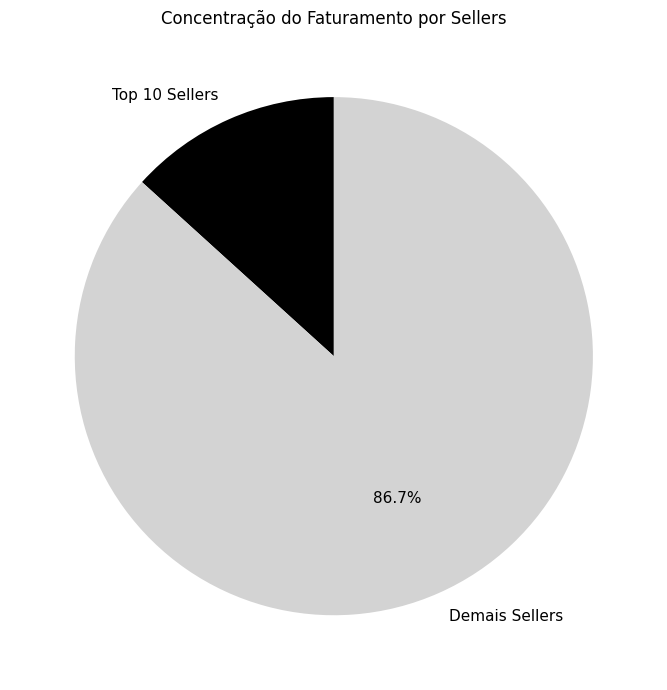

In [87]:
outros_sellers = faturamento_total - faturamento_top10

fig, ax = plt.subplots(figsize=(7, 7))

ax.pie(
    [faturamento_top10, outros_sellers],
    labels=['Top 10 Sellers', 'Demais Sellers'],
    autopct='%1.1f%%',
    colors=['black', 'lightgray'],
    startangle=90,
    textprops={'fontsize': 11}
)

ax.set_title('Concentração do Faturamento por Sellers')

fig.patch.set_alpha(0)

plt.tight_layout()
plt.show()